# Data prep: Galaxy Zoo 2 -> simple 6-class dataset

Goal: turn the volunteer vote tables into single-label classes, check them visually, and cache
cropped/resized images as a uint8 memmap so training is not bottlenecked by JPEG decoding.

**Caveat:** we only keep galaxies where volunteers clearly agreed (the Hart 2016 `*_flag` = 1 'clean sample').
~half of GZ2 is ambiguous and excluded, so test accuracy here is optimistic compared with real-world data.

In [ ]:
import os, zipfile, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from io import BytesIO
from PIL import Image
from multiprocessing import Pool
from sklearn.model_selection import train_test_split

ROOT = Path('..').resolve() if Path('..', 'data').exists() else Path('.').resolve()
RAW, OUT = ROOT/'data/raw', ROOT/'data/processed'
OUT.mkdir(parents=True, exist_ok=True)
ZIP = RAW/'zenodo/images_gz2.zip'

CROP = 224  # Centering the picture
SIZE = int(os.environ.get('MV_SIZE', 128))   # override with MV_SIZE=224 for a bigger cache
SEED = 42

## 1. Build single-label classes from the clean-sample flags

In [3]:
flag_cols = lambda c: c in ('dr7objid','total_classifications') or c.endswith('_flag')
h = pd.read_csv(RAW/'hart16/gz2_hart16.csv.gz', usecols=flag_cols)
f = lambda n: h[n] == 1
smooth = f('t01_smooth_or_features_a01_smooth_flag')
feat   = f('t01_smooth_or_features_a02_features_or_disk_flag')
CLASSES = {
    'smooth_round':     smooth & f('t07_rounded_a16_completely_round_flag'),
    'smooth_inbetween': smooth & f('t07_rounded_a17_in_between_flag'),
    'smooth_cigar':     smooth & f('t07_rounded_a18_cigar_shaped_flag'),
    'edgeon':           feat & f('t02_edgeon_a04_yes_flag'),
    'spiral':           feat & f('t02_edgeon_a05_no_flag') & f('t04_spiral_a08_spiral_flag'),
    'merger':           f('t06_odd_a14_yes_flag') & f('t08_odd_feature_a24_merger_flag'),
}
names = list(CLASSES)
M = np.stack([CLASSES[k] for k in names], 1)
n_hits = M.sum(1)
print('galaxies:', len(h), '| unlabelled (ambiguous):', (n_hits==0).sum(), '| matching >1 class (dropped):', (n_hits>1).sum())
lab = h.loc[n_hits==1, ['dr7objid']].copy()
lab['label'] = M[n_hits==1].argmax(1)
lab['cls'] = [names[i] for i in lab.label]
lab.cls.value_counts()

galaxies: 239695 | unlabelled (ambiguous): 129447 | matching >1 class (dropped): 555


cls
spiral              69327
smooth_round        14715
smooth_inbetween    14616
edgeon               9357
smooth_cigar         1583
merger                 95
Name: count, dtype: int64

## 2. Join to image files via the Zenodo mapping (objid -> asset_id) and check the zip

In [4]:
mp = pd.read_csv(RAW/'zenodo/gz2_filename_mapping.csv')
with zipfile.ZipFile(ZIP) as z:
    # the zip also holds macOS junk (__MACOSX/images/._N.jpg); keep only real images
    in_zip = {n for n in z.namelist() if n.startswith('images/') and n.endswith('.jpg')}
print('jpgs in zip:', len(in_zip), '(Zenodo says 243,434) | example:', sorted(in_zip)[:2])

df = lab.merge(mp, left_on='dr7objid', right_on='objid', how='left')
print('labelled galaxies with no mapping row:', df.asset_id.isna().sum())
df = df.dropna(subset=['asset_id']).copy()
df['asset_id'] = df.asset_id.astype(int)
df['member'] = 'images/' + df.asset_id.astype(str) + '.jpg'
print('with image in zip:', df.member.isin(in_zip).sum(), 'of', len(df))
df = df[df.member.isin(in_zip)]
dups = df.dr7objid.duplicated().sum(); print('duplicate objids (kept first):', dups)
df = df.drop_duplicates('dr7objid').reset_index(drop=True)
print(len(df), 'final galaxies')

jpgs in zip: 243434 (Zenodo says 243,434) | example: ['images/100.jpg', 'images/1000.jpg']
labelled galaxies with no mapping row: 0
with image in zip: 109673 of 109693
duplicate objids (kept first): 0
109673 final galaxies


## 3. Visual spot check - do the images match the labels?

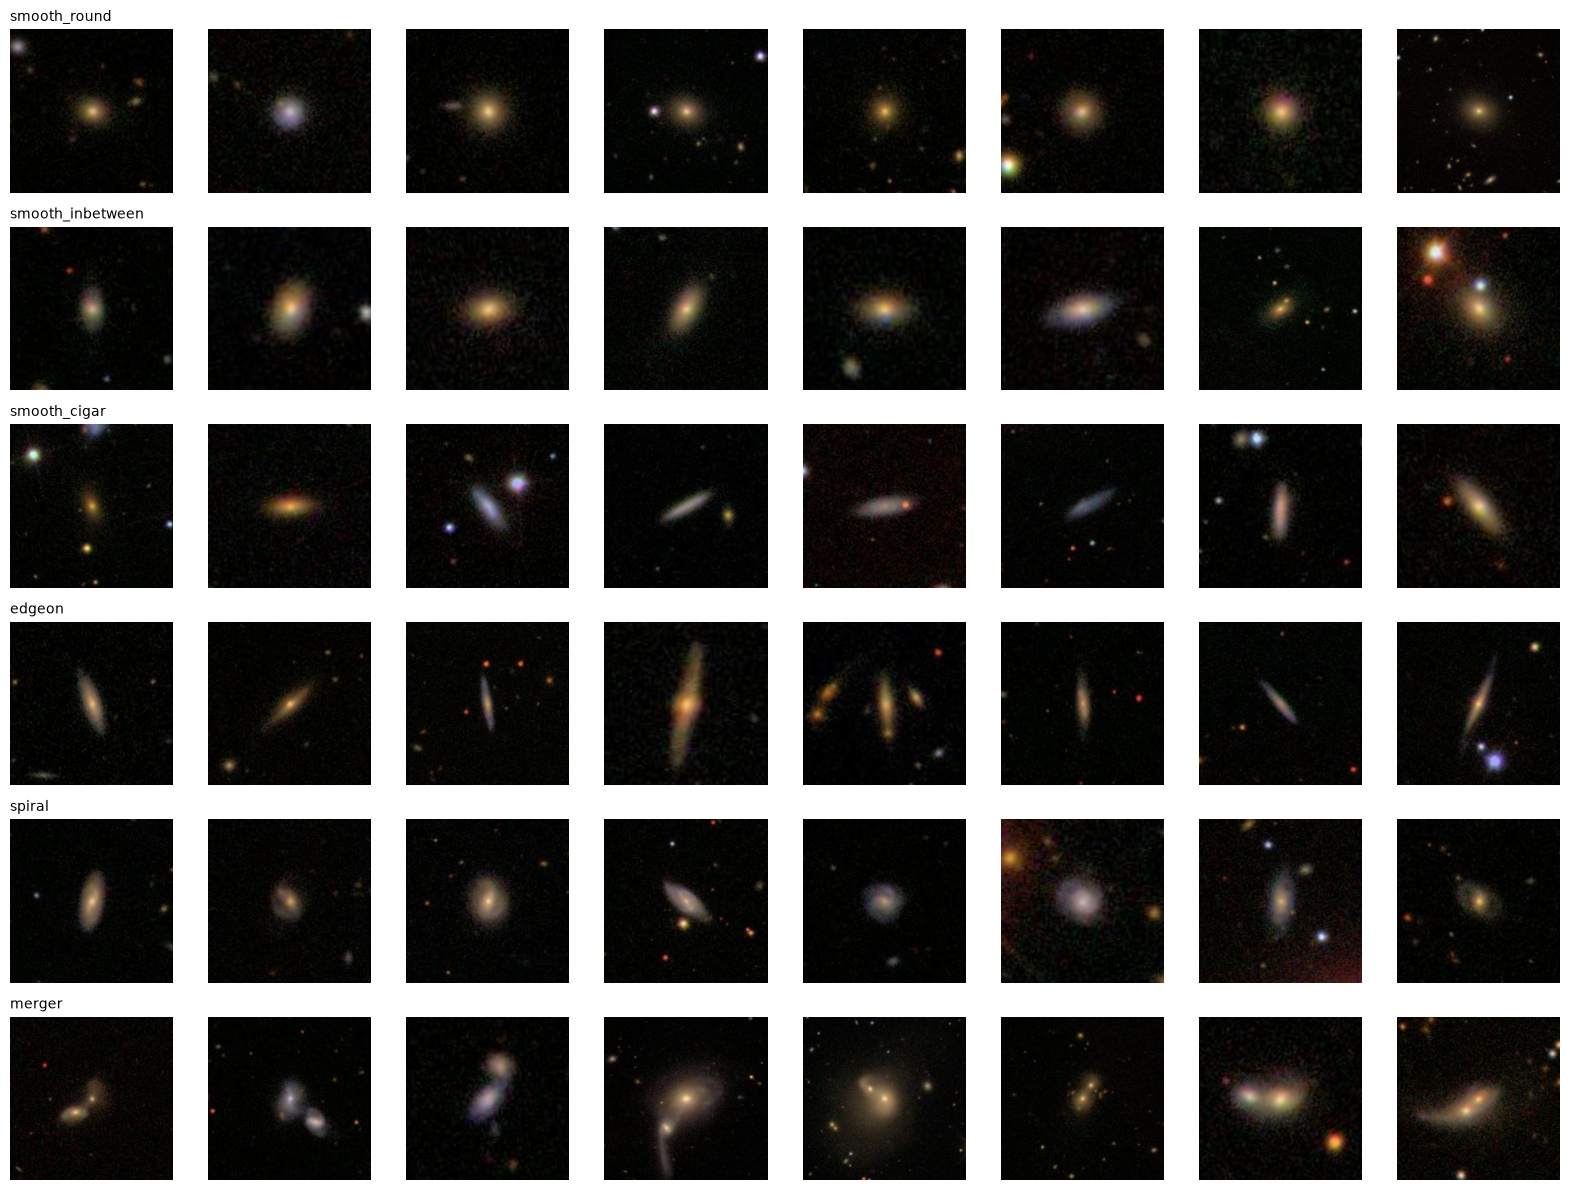

In [5]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(names), 8, figsize=(16, 2*len(names)))
with zipfile.ZipFile(ZIP) as z:
    for r, c in enumerate(names):
        pick = df[df.cls==c].sample(8, random_state=SEED)
        for a, m in zip(axes[r], pick.member):
            a.imshow(Image.open(BytesIO(z.read(m)))); a.axis('off')
        axes[r,0].set_title(c, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Fixed stratified split (70/15/15), made once

In [6]:
idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=df.label, random_state=SEED)
va, te  = train_test_split(tmp, test_size=0.50, stratify=df.label.iloc[tmp], random_state=SEED)
df['split'] = ''
df.loc[tr,'split']='train'; df.loc[va,'split']='val'; df.loc[te,'split']='test'
df[['dr7objid','asset_id','member','label','cls','split']].to_csv(OUT/'labels.csv', index=False)
pd.crosstab(df.cls, df.split)

split,test,train,val
cls,,,
edgeon,1403,6550,1404
merger,14,67,14
smooth_cigar,238,1108,237
smooth_inbetween,2192,10230,2193
smooth_round,2207,10298,2206
spiral,10397,48518,10397


## 5. Crop + resize everything once into a uint8 memmap

In [ ]:
_z = None
def load(member):
    global _z
    if _z is None: _z = zipfile.ZipFile(ZIP)
    im = Image.open(BytesIO(_z.read(member))).convert('RGB')
    w, h_ = im.size; l, t = (w-CROP)//2, (h_-CROP)//2
    im = im.crop((l, t, l+CROP, t+CROP)).resize((SIZE, SIZE), Image.LANCZOS)
    return np.asarray(im, dtype=np.uint8)

X = np.lib.format.open_memmap(OUT/f'images_{SIZE}.npy', mode='w+', dtype=np.uint8, shape=(len(df), SIZE, SIZE, 3))
with Pool() as p:
    for i, a in enumerate(p.imap(load, df.member, chunksize=256)):
        X[i] = a
X.flush(); print(X.shape, X.dtype, f'{X.nbytes/2**30:.2f} GiB')

(109673, 128, 128, 3) uint8 5.02 GiB


## 6. Sanity check: memmap content matches labels.csv row order

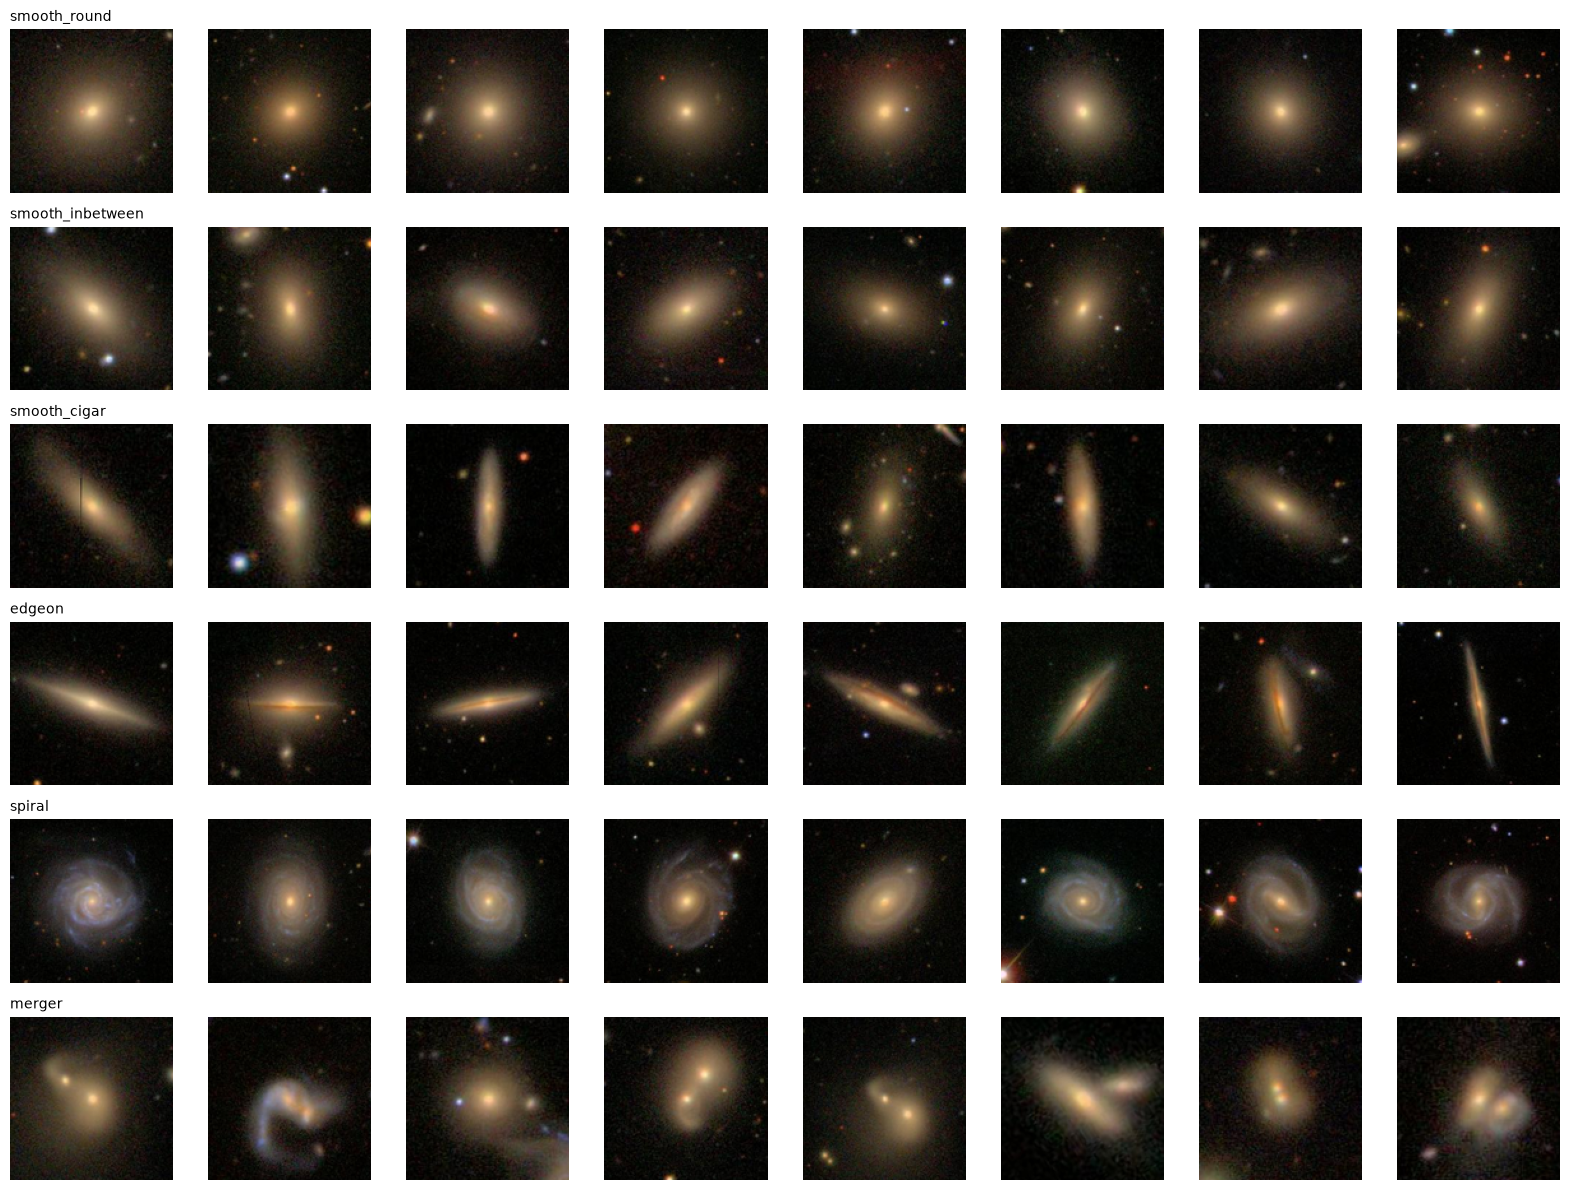

mean pixel per channel: [27.58412476 23.79072131 19.29733441] std: [37.09232947 31.27663327 27.4383699 ]


In [8]:
X = np.load(OUT/f'images_{SIZE}.npy', mmap_mode='r')
lab_df = pd.read_csv(OUT/'labels.csv')
assert len(X) == len(lab_df)
fig, axes = plt.subplots(len(names), 8, figsize=(16, 2*len(names)))
for r, c in enumerate(names):
    ids = lab_df.index[lab_df.cls==c][:8]
    for a, i in zip(axes[r], ids): a.imshow(X[i]); a.axis('off')
    axes[r,0].set_title(c, loc='left', fontsize=10)
plt.tight_layout(); plt.show()
print('mean pixel per channel:', X[:2000].reshape(-1,3).mean(0), 'std:', X[:2000].reshape(-1,3).std(0))